## 🌐 **Google Drive Connection**

In [ ]:
from google.colab import drive
drive.mount("/gdrive")
current_dir = "/gdrive/My Drive/the_reluctants_ch2"
%cd $current_dir

Mounted at /gdrive
/gdrive/My Drive/the_reluctants_ch2


## ⚙️ **Libraries Import**

In [ ]:
# Set seed for reproducibility
SEED = 42

# Ensure tensorflow and jax are compatible to prevent circular import issues with tensorboard
# This often resolves 'partially initialized module jax has no attribute _src' errors.
#!pip install --upgrade tensorflow jax

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np
import pickle

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision.transforms import v2 as transforms
from torch.utils.data import TensorDataset, DataLoader
!pip install torchview
!pip install kornia
from torchview import draw_graph

# Configurazione di TensorBoard e directory
logs_dir = "tensorboard"
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import cv2
import copy
import shutil
from itertools import product
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.gridspec as gridspec
import requests
from io import BytesIO
import time
from torch.utils.data import Dataset, DataLoader

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 25.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 106.7 MB/s eta 0:00:00
PyTorch version: 2.9.0+cu126
Device: cuda


## 🔤 **Various parameters**

In [ ]:
BATCH_SIZE = 64
num_classes = 4
RESIZE_FACTOR = 1 #dimensions of the images are divided by this factor
#RESIZE_FACTOR = 2 was used in previous iterations of this code

## ⛏**Patches Extraction Function**

In [ ]:
def extract_patches(img, original_image_filepath, patch_size=224, stride=224, bg_threshold=0.85*255, max_bg_fraction=0.80, gray_threshold=0.05*255):
    """
    Extract meaningful patches from a high-res image, filtering out mostly background or mostly gray patches.
    Now returns metadata (patch_y_coord, patch_x_coord, bg_fraction, mean_patch_color_std) for valid patches.

    Args:
        img: (H, W, 3) uint8 image in [0, 255]
        original_image_filepath (str): The full path to the original image file.
        patch_size: size of output patches (square)
        stride: patch stride (default = no overlap)
        bg_threshold: pixel values above this are considered background (0-255 scale)
        max_bg_fraction: drop patch if >80% bg pixels
        gray_threshold: patches with mean standard deviation of pixel channels below this are considered gray (0-255 scale)

    Returns:
        List of (patch_y_coord, patch_x_coord, bg_fraction, mean_patch_color_std) for valid patches.
    """
    H, W, _ = img.shape # Dimensions of the (potentially resized) input image

    valid_patch_metadata = []

    # CORRECTED: Derive mask file path by replacing 'img_' with 'mask_'
    original_image_filename = os.path.basename(original_image_filepath)
    mask_filename = original_image_filename.replace('img_', 'mask_')
    mask_filepath = os.path.join(os.path.dirname(original_image_filepath), mask_filename)

    mask = cv2.imread(mask_filepath, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        # Removed verbose debugging prints now that the filename generation is fixed
        return []

    mask = (mask > 0).astype(np.uint8) * 255

    # Ensure mask is the same size as the input image 'img'
    if mask.shape[0] != H or mask.shape[1] != W:
        mask = cv2.resize(mask, (W, H), interpolation=cv2.INTER_AREA)

    for y in range(0, H - patch_size + 1, stride):
        for x in range(0, W - patch_size + 1, stride):
            # mask dimensions are now guaranteed to match img dimensions.
            patch = img[y:y+patch_size, x:x+patch_size]
            patch_mask = mask[y:y+patch_size, x:x+patch_size]

            if (patch_mask == 255).any():
                bg_mask = (patch.mean(axis=2) > bg_threshold)
                bg_fraction = bg_mask.mean()

                if bg_fraction < max_bg_fraction:
                    pixel_channel_std = np.std(patch, axis=2)
                    mean_patch_color_std = np.mean(pixel_channel_std)

                    if mean_patch_color_std > gray_threshold:
                        valid_patch_metadata.append((y, x, bg_fraction, mean_patch_color_std))

    return valid_patch_metadata

## 📩 **DATA LOADING**

In [ ]:
#Locations of already created patch images (both local and on drive)
TRAIN_PATCH_DATA_CACHE = '/content/train_patches.pkl'
VAL_PATCH_DATA_CACHE = '/content/val_patches.pkl'

DRIVE_TRAIN_PATCH_DATA_CACHE = os.path.join(current_dir, 'train_patches.pkl')
DRIVE_VAL_PATCH_DATA_CACHE = os.path.join(current_dir, 'val_patches.pkl')

print(f"Train patch data local cache: {TRAIN_PATCH_DATA_CACHE}")
print(f"Validation patch data local cache: {VAL_PATCH_DATA_CACHE}")
print(f"Train patch data Drive cache: {DRIVE_TRAIN_PATCH_DATA_CACHE}")
print(f"Validation patch data Drive cache: {DRIVE_VAL_PATCH_DATA_CACHE}")

Train patch data local cache: /content/train_patches.pkl
Validation patch data local cache: /content/val_patches.pkl
Train patch data Drive cache: /gdrive/My Drive/the_reluctants_ch2/train_patches.pkl
Validation patch data Drive cache: /gdrive/My Drive/the_reluctants_ch2/val_patches.pkl


In [ ]:
#locations of already created preprocessed image data
# Local fast storage for cache
LOCAL_CACHE = "/content/traindata_preprocessed.npz"

# Path to NPZ in Google Drive
DRIVE_CACHE = "/gdrive/My Drive/the_reluctants_ch2/traindata_preprocessed.npz"

# If cache exists in Drive, copy it to fast storage
if os.path.exists(DRIVE_CACHE):
    shutil.copy(DRIVE_CACHE, LOCAL_CACHE)
    print("🔵 Copied cached dataset from Drive → fast local storage")
else:
    print("🟡 No cache found in Drive — will create it locally")

🔵 Copied cached dataset from Drive → fast local storage


In [ ]:
def load_or_create_cached_patch_data_for_split(
    filepaths, labels,
    local_cache_path, drive_cache_path,
    patch_size, stride, bg_threshold, max_bg_fraction, gray_threshold, resize_factor,
    dataset_type # 'train' or 'val'
):
    """
    Loads or creates a cached TensorDataset of patches, labels, and patch weights for a given data split.

    Args:
        filepaths (list): List of image filepaths.
        labels (torch.Tensor or np.ndarray): Corresponding labels for each image.
        local_cache_path (str): Path to the local .pkl file for caching.
        drive_cache_path (str): Path to the Drive .pkl file for persistent caching.
        patch_size (int): Size of the square patches.
        stride (int): Stride for patch extraction.
        bg_threshold (float): Background threshold for patch extraction.
        max_bg_fraction (float): Maximum background fraction for patch filtering.
        gray_threshold (float): Grayness threshold for patch filtering.
        resize_factor (int): Factor to resize images before patch extraction.
        dataset_type (str): Type of dataset ('train' or 'val') for logging purposes.

    Returns:
        torch.utils.data.TensorDataset: Dataset containing patch tensors, label tensors, and patch weight tensors.
    """
    # 1. Check for local cache
    if os.path.exists(local_cache_path):
        print(f"🔵 Loading {dataset_type} patch data from fast local storage ({local_cache_path})...")
        with open(local_cache_path, 'rb') as f:
            cached_data = pickle.load(f)
        all_patches_tensor, all_labels_tensor, all_patch_weights_tensor = cached_data
        print(f"Loaded {len(all_patches_tensor)} patches for {dataset_type}.")
        return TensorDataset(all_patches_tensor, all_labels_tensor, all_patch_weights_tensor)

    # 2. If no local cache, check for Drive cache and copy it locally
    elif os.path.exists(drive_cache_path):
        print(f"🔵 Drive cache found for {dataset_type} patch data. Copying from Drive → fast local storage...")
        shutil.copy(drive_cache_path, local_cache_path)
        with open(local_cache_path, 'rb') as f:
            cached_data = pickle.load(f)
        all_patches_tensor, all_labels_tensor, all_patch_weights_tensor = cached_data
        print(f"Loaded {len(all_patches_tensor)} patches for {dataset_type}.")
        return TensorDataset(all_patches_tensor, all_labels_tensor, all_patch_weights_tensor)

    # 3. If neither cache exists, generate patches locally
    print(f"🟡 No cache found for {dataset_type} patch data — creating it locally...")

    # Instantiate PatchDataset to generate patches and load into RAM
    patch_dataset = PatchDataset(
        filepaths=filepaths,
        labels=labels.numpy(), # Convert labels to numpy for PatchDataset constructor
        patch_size=patch_size,
        stride=stride,
        bg_threshold=bg_threshold,
        max_bg_fraction=max_bg_fraction,
        gray_threshold=gray_threshold,
        resize_factor=resize_factor
    )

    # Convert collected patches and labels into tensors for TensorDataset
    all_patches_tensor = torch.stack(patch_dataset.patches)
    all_labels_tensor = torch.stack(patch_dataset.labels)
    all_patch_weights_tensor = torch.stack(patch_dataset.patch_weights)

    # Free up memory from the temporary PatchDataset storage
    del patch_dataset.patches, patch_dataset.labels, patch_dataset.patch_weights
    gc.collect()

    print(f"💾 Saving {dataset_type} patch data cache locally and to Drive...")
    with open(local_cache_path, 'wb') as f:
        pickle.dump((all_patches_tensor, all_labels_tensor, all_patch_weights_tensor), f)

    # Also save to Drive for future runs
    shutil.copy(local_cache_path, drive_cache_path)
    print(f"📤 {dataset_type} cache synced to Drive.")

    dataset = TensorDataset(all_patches_tensor, all_labels_tensor, all_patch_weights_tensor)

    # Clear tensors from memory after saving them to disk
    del all_patches_tensor, all_labels_tensor, all_patch_weights_tensor
    gc.collect()

    return dataset

In [ ]:
import gc

label_mapping = {
    'Luminal B': 0,
    'Luminal A': 1,
    'HER2(+)': 2,
    'Triple negative': 3
}

def load_images_from_folder(folder, labels_df):
    """
    Returns a list of (image_filepath, label_num) tuples for each image in the folder.
    Does not load actual image data or extract patches.
    """
    metadata_list = []

    for filename in os.listdir(folder):
        if not filename.lower().endswith(('.png', '.jpg', '.jpeg')):
            continue # Skip non-image files

        if filename.startswith("mask"):
            continue # Skip mask files

        # Construct full filepath
        filepath = os.path.join(folder, filename)

        # Get string label from DataFrame
        label_str = labels_df.loc[labels_df['sample_index'] == filename, 'label'].values[0]

        # Map to numerical label
        label_num = label_mapping[label_str]

        # Append (filepath, numerical_label) tuple to metadata list
        metadata_list.append((filepath, label_num))

    return metadata_list


def load_or_create_cache(folder, local_cache_path, drive_cache_path):
    # This function caches metadata (filepaths and labels) instead of image data.
    # The actual image loading and preprocessing will happen later in a custom Dataset.

    # FAST PATH — load from /content if exists
    if os.path.exists(local_cache_path):
        print("🔵 Loading dataset metadata from fast local storage (/content)...")
        data = np.load(local_cache_path, allow_pickle=True)
        # Cache will now store filepaths and numerical labels
        filepaths = data["filepaths"]
        labels_num = data["labels_num"]
        return filepaths, labels_num

    # SLOW PATH — need to build cache
    print("🟡 No local cache for metadata — creating it locally...")
    labels_df = pd.read_csv("train_labels.csv") # Load labels_df here
    metadata_list = load_images_from_folder(folder, labels_df)

    # Separate filepaths and labels from the metadata list
    filepaths = np.array([item[0] for item in metadata_list])
    labels_num = np.array([item[1] for item in metadata_list])

    print("💾 Saving metadata cache locally and to Drive...")
    np.savez_compressed(local_cache_path, filepaths=filepaths, labels_num=labels_num)

    # Also save to Drive for future runs
    shutil.copy(local_cache_path, drive_cache_path)
    print("📤 Cache synced to Drive.")

    return filepaths, labels_num


# -------------------------
# LOAD DATASET METADATA
# -------------------------

# Folder with raw images (inside my Drive directory)
img_path = "/gdrive/My Drive/the_reluctants_ch2/train_data_updated"

# Load or create cache for metadata
filepaths, labels_num = load_or_create_cache(img_path, LOCAL_CACHE, DRIVE_CACHE)

print(f"Loaded {len(filepaths)} image filepaths")
print(f"Loaded {len(labels_num)} numeric labels")

# Convert labels to torch tensor (no images_tensor yet)
labels_tensor = torch.tensor(labels_num, dtype=torch.long).squeeze() # (N,)

print("Converted to tensors: ", labels_tensor.shape)

del labels_num # Free the numpy array to save RAM
gc.collect()

🔵 Loading dataset metadata from fast local storage (/content)...
Loaded 581 image filepaths
Loaded 581 numeric labels
Converted to tensors:  torch.Size([581])


82

In [ ]:
import tqdm # Import tqdm for progress bars

class PatchDataset(Dataset):
    def __init__(self, filepaths, labels, patch_size=224, stride=224, bg_threshold=0.85, max_bg_fraction=0.80, gray_threshold=0.05, resize_factor=1):
        self.patches = []  # Stores actual patch tensors
        self.labels = []   # Stores corresponding labels
        self.patch_weights = [] # Stores calculated weights for each patch
        self.no_patch_filepaths = [] # Stores filepaths for images with no extracted patches
        self.patch_size = patch_size
        self.stride = stride
        self.bg_threshold = bg_threshold
        self.max_bg_fraction = max_bg_fraction
        self.gray_threshold = gray_threshold
        self.resize_factor = resize_factor

        # Wrap the filepath iteration with tqdm
        # desc will show the current status
        # leave=False means the progress bar will disappear once the loop is done
        for i, filepath in tqdm.tqdm(enumerate(filepaths), total=len(filepaths), desc="Generating and loading patches"):
            current_label = labels[i] # Get the label for the current image

            # Load image (from disk)
            img = cv2.imread(filepath)
            if img is None:
                print(f"Warning: Could not load image {filepath}. Skipping.")
                self.no_patch_filepaths.append(filepath) # Record if image cannot be loaded
                continue

            # NEW: Resize the image before patch extraction
            if self.resize_factor > 1:
                new_h = img.shape[0] // self.resize_factor
                new_w = img.shape[1] // self.resize_factor
                img = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)


            # Image is already uint8 (0-255) from cv2.imread. No normalization here.
            img_rgb = img[..., ::-1]  # BGR to RGB, still uint8

            # Extract metadata of valid patches using the modified extract_patches
            valid_metadata = extract_patches(
                img_rgb,
                original_image_filepath=filepath, # Pass the original image filepath
                patch_size=self.patch_size,
                stride=self.stride,
                bg_threshold=self.bg_threshold * 255, # Scale bg_threshold for uint8 input
                max_bg_fraction=self.max_bg_fraction,
                gray_threshold=self.gray_threshold * 255 # Scale gray_threshold for uint8 input
            )

            if not valid_metadata:
                self.no_patch_filepaths.append(filepath) # Record if no valid patches found
                continue # Skip to next image if no patches were extracted

            # Store metadata for each valid patch
            for y_coord, x_coord, bg_fraction, mean_patch_color_std in valid_metadata:
                patch = img_rgb[y_coord : y_coord + self.patch_size, x_coord : x_coord + self.patch_size]

                # Ensure 'patch' is a numpy array.
                if not isinstance(patch, np.ndarray):
                    print(f"Warning: Patch from {filepath} is of type {type(patch)}, expected numpy.ndarray. Attempting conversion.")
                    try:
                        patch = np.array(patch, dtype=np.uint8) # Ensure it's uint8 before normalization
                    except Exception as e:
                        raise TypeError(f"Could not convert unexpected patch type {type(patch)} to numpy array: {e}")

                # Convert patch to float32 and normalize to [0, 1] AFTER extraction
                patch = (patch / 255.0).astype(np.float32)

                # Convert patch to PyTorch tensor (C, H, W)
                patch_tensor = torch.tensor(patch, dtype=torch.float32).permute(2, 0, 1)

                # Calculate patch weight (e.g., inverse of background fraction, with a minimum)
                # We ensure the weight is never zero by adding a small epsilon or setting a floor.
                patch_weight = torch.tensor(max(0.01, 1.0 - bg_fraction), dtype=torch.float32)

                self.patches.append(patch_tensor)
                self.labels.append(torch.tensor(current_label, dtype=torch.long))
                self.patch_weights.append(patch_weight)

            # Removed 'patch' and 'patch_tensor' from the del statement as they might not be defined
            del img, img_rgb, valid_metadata, current_label

        print(f"Finished loading {len(self.patches)} patches into RAM.")

    def __len__(self):
        # The length of the dataset is now the number of valid patches found
        return len(self.patches)

    def __getitem__(self, idx):
        # Retrieve the pre-loaded patch, label, and its weight
        return self.patches[idx], self.labels[idx], self.patch_weights[idx]

**DATA PREPROCESSING**

In [ ]:
IMG_SIZE = 224 #Size of patches

X_train_filepaths, X_val_filepaths, y_train, y_val = train_test_split(
    filepaths,
    labels_tensor,
    test_size=0.2,
    random_state=SEED,
    stratify=labels_tensor
)

# Free up memory from original data after splitting
del filepaths, labels_tensor
gc.collect()

# Create datasets using the new caching function
train_dataset_transformed = load_or_create_cached_patch_data_for_split(
    filepaths=X_train_filepaths,
    labels=y_train, # y_train is already a torch.Tensor
    local_cache_path=TRAIN_PATCH_DATA_CACHE,
    drive_cache_path=DRIVE_TRAIN_PATCH_DATA_CACHE,
    patch_size=IMG_SIZE,
    stride=IMG_SIZE,
    bg_threshold=0.8,
    max_bg_fraction=0.75,
    gray_threshold=0.01,
    resize_factor=RESIZE_FACTOR,
    dataset_type='train'
)

val_dataset_transformed = load_or_create_cached_patch_data_for_split(
    filepaths=X_val_filepaths,
    labels=y_val, # y_val is already a torch.Tensor
    local_cache_path=VAL_PATCH_DATA_CACHE,
    drive_cache_path=DRIVE_VAL_PATCH_DATA_CACHE,
    patch_size=IMG_SIZE,
    stride=IMG_SIZE,
    bg_threshold=0.8,
    max_bg_fraction=0.75,
    gray_threshold=0.01,
    resize_factor=RESIZE_FACTOR,
    dataset_type='val'
)

# Free up memory from split data after datasets are initialized
del X_train_filepaths, X_val_filepaths, y_train, y_val
gc.collect()

print(f"Training dataset size: {len(train_dataset_transformed)}")
print(f"Validation dataset size: {len(val_dataset_transformed)}")

🔵 Drive cache found for train patch data. Copying from Drive → fast local storage...
Loaded 2154 patches for train.
🔵 Drive cache found for val patch data. Copying from Drive → fast local storage...
Loaded 579 patches for val.
Training dataset size: 2154
Validation dataset size: 579


### Display Sample Patches

In [ ]:
def visualize_patches(dataset, num_patches_to_display, title='Sample Patches'):
    """
    Visualizes a specified number of patches from a given dataset in a matplotlib grid.

    Args:
        dataset: A PyTorch Dataset object that returns (patch_tensor, label_tensor, patch_weight_tensor).
        num_patches_to_display (int): The total number of patches to display.
        title (str, optional): The title for the entire plot. Defaults to 'Sample Patches'.
    """
    # Calculate grid dimensions
    num_cols = int(np.ceil(np.sqrt(num_patches_to_display)))
    num_rows = int(np.ceil(num_patches_to_display / num_cols))

    fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 3, num_rows * 3))
    axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

    print(f"Displaying {num_patches_to_display} patches from the dataset...")

    for i in range(num_patches_to_display):
        if i >= len(dataset):
            print(f"Warning: Only {i} patches available in the dataset, requested {num_patches_to_display}.")
            break

        # Corrected: Unpack all three returned values, ignore the third (patch_weight)
        patch, label, _ = dataset[i]

        ax = axes[i]

        # Convert PyTorch tensor (C, H, W) to NumPy array (H, W, C) for imshow
        # And convert to CPU if it's on GPU
        patch_np = patch.permute(1, 2, 0).cpu().numpy()

        ax.imshow(patch_np)
        ax.set_title(f"Label: {label.item()}")
        ax.axis('off')

    # Turn off any unused subplots
    for j in range(num_patches_to_display, len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle(title, fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make space for suptitle
    plt.show()
    plt.close()

In [ ]:
visualize_patches(train_dataset_transformed, num_patches_to_display=200, title='Sample Patches from Training Dataset')

## **Dataset Label Balance Analysis**

Train Dataset Label Distribution:

Luminal B          790
Luminal A          575
HER2(+)            557
Triple negative    232
Name: count, dtype: int64


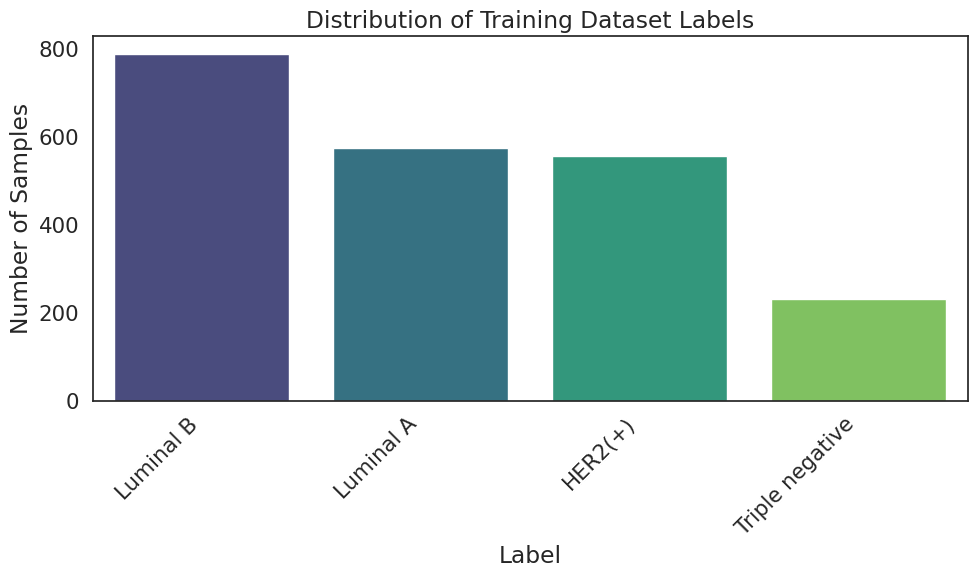


Validation Dataset Label Distribution:

Luminal B          209
HER2(+)            154
Luminal A          148
Triple negative     68
Name: count, dtype: int64


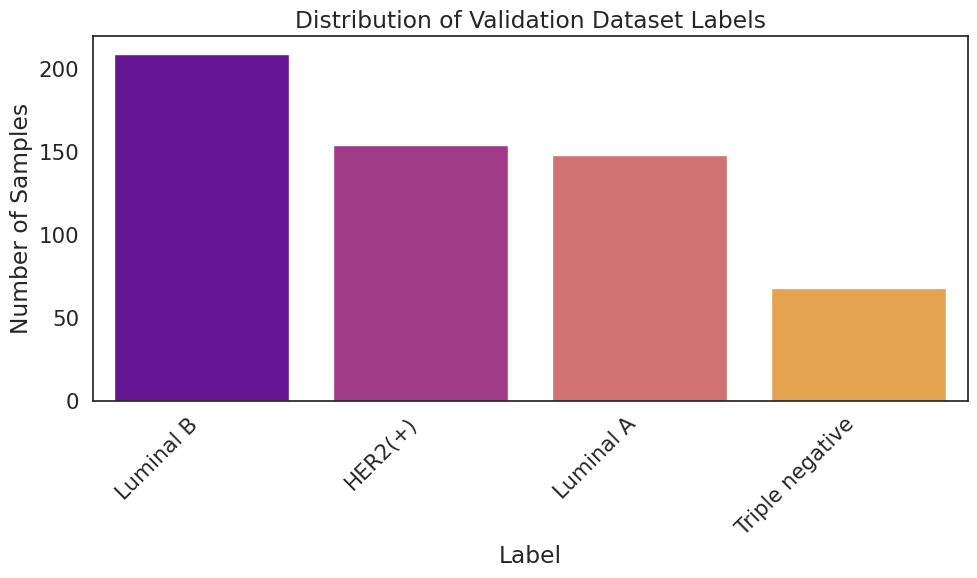

In [ ]:
inverse_label_mapping = {v: k for k, v in label_mapping.items()}

# --- Training Dataset Label Distribution ---
# Get all numeric labels from the training dataset
train_numeric_labels = [label.item() for label in train_dataset_transformed.tensors[1]]
# Convert numeric labels to string labels for better readability
train_string_labels = [inverse_label_mapping[num_label] for num_label in train_numeric_labels]

train_label_counts = pd.Series(train_string_labels).value_counts()

print("Train Dataset Label Distribution:\n")
print(train_label_counts)

plt.figure(figsize=(10, 6))
sns.barplot(x=train_label_counts.index, y=train_label_counts.values, palette='viridis')
plt.title('Distribution of Training Dataset Labels')
plt.xlabel('Label')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
plt.close()

# --- Validation Dataset Label Distribution ---
# Get all numeric labels from the validation dataset
val_numeric_labels = [label.item() for label in val_dataset_transformed.tensors[1]]
# Convert numeric labels to string labels for better readability
val_string_labels = [inverse_label_mapping[num_label] for num_label in val_numeric_labels]

val_label_counts = pd.Series(val_string_labels).value_counts()

print("\nValidation Dataset Label Distribution:\n")
print(val_label_counts)

plt.figure(figsize=(10, 6))
sns.barplot(x=val_label_counts.index, y=val_label_counts.values, palette='plasma')
plt.title('Distribution of Validation Dataset Labels')
plt.xlabel('Label')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
plt.close()

## 🌀 **Image Augmentation**

The Kornia library was used to apply augmentations directly on GPU during training, in order to speed up the training process. The augmentations that are commented out were removed to obtain better results, such as higher accuracy.

In [ ]:
#With Kornia
import kornia.augmentation as K
import kornia.filters as KF
import torch.nn as nn
# Define image transformations for training and validation

#IMG_SIZE = 224

train_transform_kornia = K.AugmentationSequential(

    # --- Geometry ---
    K.RandomResizedCrop((IMG_SIZE, IMG_SIZE), scale=(0.90, 1.0), p=1.0),
    K.RandomHorizontalFlip(p=0.5),
    K.RandomVerticalFlip(p=0.5),
    K.RandomRotation(degrees=5.0, p=0.4),
    K.RandomAffine(degrees=0, translate=(0.05, 0.05),
                   scale=(0.95, 1.05), shear=0),

    # --- Stain / Color ---
    K.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1,
        hue=0.05,
        p=0.4,
    ),

    # --- Blur / Noise ---
    #K.RandomGaussianBlur((3,3), sigma=(0.1, 1.5), p=0.3),
    #K.RandomGaussianNoise(mean=0.0, std=0.02, p=0.3),

    # # --- Histology deformation ---
    # K.RandomElasticTransform(
    #     kernel_size=(31, 31),
    #     sigma=(5, 5),
    #     alpha=(1, 1),
    #     p=0.25,                  # mild deformation only
    # ),

    # --- Random selection block ---
    # K.RandomChoice is not available in Kornia 0.8.2
    # K.RandomChoice([
    #     K.RandomSharpness(sharpness=0.3, p=1.0),
    #     K.RandomMotionBlur(3, angle=15, direction=0.3, p=1.0),
    #     K.RandomBrightness(0.05, p=1.0),
    #     K.RandomContrast(0.10, p=1.0),
    # ], p=0.3),                  # 30% chance apply ONE of these

    # --- Normalization ---
    K.Normalize(mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]),
    data_keys=["input"],
)

print(f"Training dataset size: {len(train_dataset_transformed)}")
print(f"Validation dataset size: {len(val_dataset_transformed)}")

Training dataset size: 2154
Validation dataset size: 579


## ⚙ **Model building**

**CREATE DATALOADER**


In [ ]:
def make_loader(ds, batch_size, shuffle, drop_last):
    """
    Create a PyTorch DataLoader with optimized settings.

    Args:
        ds (Dataset): PyTorch Dataset object
        batch_size (int): Number of samples per batch
        shuffle (bool): Whether to shuffle data at each epoch
        drop_last (bool): Whether to drop last incomplete batch

    Returns:
        DataLoader: Configured DataLoader instance
    """
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))
    num_workers = 8
    print(num_workers)

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,  # Load 4 batches ahead
    )

batch_size = BATCH_SIZE

train_loader = make_loader(train_dataset_transformed, batch_size, shuffle=True, drop_last=True)
val_loader = make_loader(val_dataset_transformed,batch_size=batch_size,shuffle=False,drop_last=False)


8
8


**BUILD THE MODEL**

In [ ]:
class CustomTransferLearningModel(nn.Module):
    """
    General transfer learning module supporting various torchvision models.
    """

    def __init__(self, num_classes, model_name="resnet18",
                 dropout_rate=0.3, freeze_backbone=True):

        super().__init__()

        # Load backbone and weights
        if model_name.startswith("resnet"):
            if model_name == "resnet18":
                weights = torchvision.models.ResNet18_Weights.DEFAULT
            elif model_name == "resnet34":
                weights = torchvision.models.ResNet34_Weights.DEFAULT
            else:
                raise ValueError(f"Unsupported ResNet model_name: {model_name}")
            self.backbone = getattr(torchvision.models, model_name)(weights=weights)
            in_features = self.backbone.fc.in_features
            # Replace classifier head
            self.backbone.fc = nn.Sequential(
                nn.Dropout(p=dropout_rate),
                nn.Linear(in_features, num_classes)
            )
        elif model_name.startswith("convnext"):
            if model_name == "convnext_tiny":
                weights = torchvision.models.ConvNeXt_Tiny_Weights.DEFAULT
            elif model_name == "convnext_small":
                weights = torchvision.models.ConvNeXt_Small_Weights.DEFAULT
            elif model_name == "convnext_base":
                weights = torchvision.models.ConvNeXt_Base_Weights.DEFAULT
            elif model_name == "convnext_large":
                weights = torchvision.models.ConvNeXt_Large_Weights.DEFAULT
            else:
                raise ValueError(f"Unsupported ConvNeXt model_name: {model_name}")
            self.backbone = getattr(torchvision.models, model_name)(weights=weights)
            in_features = self.backbone.classifier[2].in_features
            # Replace classifier head
            self.backbone.classifier[2] = nn.Sequential(
                nn.Dropout(p=dropout_rate),
                nn.Linear(in_features, num_classes)
            )
        else:
            raise ValueError(f"Unsupported model_name: {model_name}")

        # Freeze backbone parameters
        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False
            # Ensure the new classifier head parameters are trainable
            if model_name.startswith("resnet"):
                for param in self.backbone.fc.parameters():
                    param.requires_grad = True
            elif model_name.startswith("convnext"):
                for param in self.backbone.classifier[2].parameters():
                    param.requires_grad = True

    def forward(self, x):
        return self.backbone(x)


**TRAIN ONE EPOCH**

In [ ]:
# Initialize best model tracking variables
best_model = None
best_performance = float('-inf')

In [ ]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device, l1_lambda=0, l2_lambda=0):
    """
    Perform one complete training epoch through the entire training dataset.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches (inputs, targets, weights)
        criterion (nn.Module): Loss function (FocalLoss expected to return per-sample loss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): Lambda for L1 regularization
        l2_lambda (float): Lambda for L2 regularization

    Returns:
        tuple: (average_loss, f1 score) - Training loss and f1 score for this epoch
    """
    model.train()  # Set model to training mode

    running_loss_sum = 0.0 # Changed to sum for per-sample losses
    total_samples = 0
    all_predictions = []
    all_targets = []

    # Iterate through training batches
    for batch_idx, (inputs, targets, weights) in enumerate(train_loader): # Unpack weights
        # Handle cases where inputs/targets/weights might be lists due to collation issues
        if isinstance(inputs, list):
            inputs = torch.stack(inputs) # Stack list of tensors into one tensor
        if isinstance(targets, list):
            targets = torch.stack(targets) # Stack list of tensors into one tensor
        if isinstance(weights, list):
            weights = torch.stack(weights) # Stack list of tensors into one tensor

        total_samples += inputs.size(0)
        batch_start = time.time()
        # Move data to device (GPU/CPU)
        inputs = inputs.to(device, non_blocking=True).float()
        targets = targets.to(device, non_blocking=True)
        weights = weights.to(device, non_blocking=True) # Move weights to device

        # GPU AUGMENTATION (if provided)
        if train_transform_kornia:
            inputs = train_transform_kornia(inputs)

        # Clear gradients from previous step
        optimizer.zero_grad(set_to_none=True)

        # Forward pass with mixed precision (if CUDA available)
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs)
            per_sample_loss = criterion(logits, targets) # Get per-sample loss
            loss = (per_sample_loss * weights).mean()    # Apply weights and take mean

            # Add L1 and L2 regularization
            l1_norm = sum(p.abs().sum() for p in model.parameters() if p.requires_grad)
            l2_norm = sum(p.pow(2).sum() for p in model.parameters() if p.requires_grad)
            loss = loss + l1_lambda * l1_norm + l2_lambda * l2_norm

        # Backward pass with gradient scaling
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_time = time.time() - batch_start
        if batch_idx < 5:  # only print first few for debug
          print(f"Batch {batch_idx} time: {batch_time:.4f}s, GPU mem: {torch.cuda.memory_allocated()/1e9:.3f} GB")

        # Accumulate metrics
        running_loss_sum += loss.item() * inputs.size(0) # Accumulate mean loss * batch size
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss_sum / total_samples
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache() # Clear unused GPU memory after epoch

    return epoch_loss, epoch_f1

**VALIDATE ONE EPOCH**

In [ ]:
def validate_one_epoch(model, val_loader, criterion, device):
    """
    Perform one complete validation epoch through the entire validation dataset.

    Args:
        model (nn.Module): The neural network model to evaluate (must be in eval mode)
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches (inputs, targets, weights (ignored))
        criterion (nn.Module): Loss function (FocalLoss expected to return per-sample loss)
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)

    Returns:
        tuple: (average_loss, accuracy) - Validation loss and accuracy for this epoch

    Note:
        This function automatically sets the model to evaluation mode and disables
        gradient computation for efficiency during validation.
    """
    model.eval()  # Set model to evaluation mode

    running_loss_sum = 0.0 # Changed to sum for per-sample losses
    total_samples = 0
    all_predictions = []
    all_targets = []

    # Disable gradient computation for validation
    with torch.no_grad():
        for inputs, targets, _ in val_loader: # Unpack and ignore weights
            total_samples += inputs.size(0)
            # Move data to device
            inputs, targets = inputs.to(device, non_blocking=True).float(), targets.to(device, non_blocking=True)

            # Apply only normalization (no augmentation)
            normalized_inputs = K.Normalize(
                mean=torch.tensor([0.485, 0.456, 0.406], device=device),
                std=torch.tensor([0.229, 0.224, 0.225], device=device)
            )(inputs)

            # Forward pass with mixed precision (if CUDA available)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(normalized_inputs)
                per_sample_loss = criterion(logits, targets) # Get per-sample loss
                loss = per_sample_loss.mean()                 # Take mean for validation loss

            # Accumulate metrics
            running_loss_sum += loss.item() * inputs.size(0) # Accumulate mean loss * batch size
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss_sum / total_samples
    epoch_accuracy = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache() # Clear unused GPU memory after epoch

    return epoch_loss, epoch_accuracy

In [ ]:
def log_metrics_to_tensorboard(writer, epoch, train_loss, train_f1, val_loss, val_f1, model):
    """
    Log training metrics and model parameters to TensorBoard for visualization.

    Args:
        writer (SummaryWriter): TensorBoard SummaryWriter object for logging
        epoch (int): Current epoch number (used as x-axis in TensorBoard plots)
        train_loss (float): Training loss for this epoch
        train_f1 (float): Training f1 score for this epoch
        val_loss (float): Validation loss for this epoch
        val_f1 (float): Validation f1 score for this epoch
        model (nn.Module): The neural network model (for logging weights/gradients)

    Note:
        This function logs scalar metrics (loss/f1 score) and histograms of model
        parameters and gradients, which helps monitor training progress and detect
        issues like vanishing/exploding gradients.
    """
    # Log scalar metrics
    writer.add_scalar('Loss/Training', train_loss, epoch)
    writer.add_scalar('Loss/Validation', val_loss, epoch)
    writer.add_scalar('F1/Training', train_f1, epoch)
    writer.add_scalar('F1/Validation', val_f1, epoch)

    # Log model parameters and gradients
    for name, param in model.named_parameters():
        if param.requires_grad:
            # Check if the tensor is not empty before adding a histogram
            if param.numel() > 0:
                writer.add_histogram(f'{name}/weights', param.data, epoch)
            if param.grad is not None:
                # Check if the gradient tensor is not empty before adding a histogram
                if param.grad.numel() > 0:
                    if param.grad is not None and torch.isfinite(param.grad).all():
                        writer.add_histogram(f'{name}/gradients', param.grad.data, epoch)

**FIT**

In [ ]:
def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, writer=None, verbose=10, experiment_name=""):
    """
    Train the neural network model on the training data and validate on the validation data.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        epochs (int): Number of training epochs
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): L1 regularization coefficient (default: 0)
        l2_lambda (float): L2 regularization coefficient (default: 0)
        patience (int): Number of epochs to wait for improvement before early stopping (default: 0)
        evaluation_metric (str): Metric to monitor for early stopping (default: "val_f1")
        mode (str): 'max' for maximizing the metric, 'min' for minimizing (default: 'max')
        restore_best_weights (bool): Whether to restore model weights from best epoch (default: True)
        writer (SummaryWriter, optional): TensorBoard SummaryWriter object for logging (default: None)
        verbose (int, optional): Frequency of printing training progress (default: 10)
        experiment_name (str, optional): Experiment name for saving models (default: "")

    Returns:
        tuple: (model, training_history) - Trained model and metrics history
    """

    # Initialize metrics tracking
    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': []
    }

    # Configure early stopping if patience is set
    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")
    prev = time.time()
    # Main training loop: iterate through epochs
    for epoch in range(1, epochs + 1):

        epoch_start = time.time()

        train_start = time.time()
        # Forward pass through training data, compute gradients, update weights
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device, l1_lambda, l2_lambda
        )

        val_start = time.time()
        # Evaluate model on validation data without updating weights
        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )
        train_time = time.time() - train_start
        val_time = time.time() - val_start

        epoch_time = time.time() - epoch_start

        gpu_mem = torch.cuda.memory_allocated() / 1024**3

        # Store metrics for plotting and analysis
        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)

        # Write metrics to TensorBoard for visualization
        if writer is not None:
            log_metrics_to_tensorboard(
                writer, epoch, train_loss, train_f1, val_loss, val_f1, model
            )

        # Print progress every N epochs or on first epoch
        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, F1 Score={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1 Score={val_f1:.4f}"
                    f"  GPU mem | {gpu_mem:.2f} GB\n"
                    f"  TOTAL epoch time: {epoch_time:.2f}s")

        # Early stopping logic: monitor metric and save best model
        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    # Restore best model weights if early stopping was used
    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load("models/"+experiment_name+'_model.pt'))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    # Save final model if no early stopping
    if patience == 0:
        torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')

    # Clear any remaining cached GPU memory after training
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # Close TensorBoard writer
    if writer is not None:
        writer.close()

    return model, training_history

**CREATE THE MODEL**

In [ ]:
y_train_np = np.array([label.item() for label in train_dataset_transformed.tensors[1]])
class_counts = np.bincount(y_train_np)
total_samples = len(y_train_np)
class_weights = total_samples / class_counts  # do NOT normalize
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("Class Counts:", class_counts)
print("Normalized Class Weights:", class_weights)
print("Class Weights Tensor on device:", class_weights_tensor)

del y_train_np, class_counts, total_samples, class_weights # Free memory
gc.collect()

Class Counts: [790 575 557 232]
Normalized Class Weights: [2.72658228 3.74608696 3.86714542 9.28448276]
Class Weights Tensor on device: tensor([2.7266, 3.7461, 3.8671, 9.2845], device='cuda:0')


414392

In [ ]:
import torch.nn.functional as F

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2, label_smoothing=0.0, ignore_index=-100):
        super(FocalLoss, self).__init__()
        self.alpha = alpha # Weighting factor for each class
        self.gamma = gamma # Focusing parameter
        self.label_smoothing = label_smoothing # New parameter for soft labeling
        self.ignore_index = ignore_index

        if alpha is not None:
            if not isinstance(alpha, torch.Tensor):
                self.alpha = torch.tensor(alpha, dtype=torch.float32)

    def forward(self, inputs, targets):
        # Ensure inputs are logits for CrossEntropyLoss
        # Inputs: (N, C), Targets: (N)

        if self.alpha is not None:
            self.alpha = self.alpha.to(inputs.device) # Move alpha to the same device as inputs

        # Use F.cross_entropy with reduction='none' and label_smoothing
        ce_loss = F.cross_entropy(
            inputs, targets,
            reduction='none',
            weight=self.alpha,
            label_smoothing=self.label_smoothing, # Apply label smoothing here
            ignore_index=self.ignore_index
        )
        pt = torch.exp(-ce_loss) # Probability of the correct class

        focal_loss = ((1 - pt)**self.gamma) * ce_loss

        return focal_loss # Always return per-sample loss, reduction will be handled outside

For transfer learning, we use a ConvNeXt-Tiny model, which is particularly good at classification on medical images like the ones in our dataset. Label smoothing has been implemented with the goal of improving generalization, while the FocalLoss function has been introduce to counter class imbalance.

In [ ]:
#PARAMETERS
LEARNING_RATE = 1.5e-3
EPOCHS = 400
PATIENCE = 30

# Regularisation
DROPOUT_RATE = 0.1         # Dropout probability
L1_LAMBDA = 0              # L1 penalty
L2_LAMBDA = 1e-5              # L2 penalty
LABEL_SMOOTHING = 0.1      # Parameter for soft labeling

# Set up loss function
criterion = FocalLoss(alpha=class_weights_tensor, gamma=2.5, label_smoothing=LABEL_SMOOTHING) # Using FocalLoss with label smoothing

In [ ]:
# Define the input shape based on the patch size and number of channels
# Patches are (C, H, W) where C=3 for RGB, and H=W=IMG_SIZE
input_shape = (3, IMG_SIZE, IMG_SIZE)
print(f"Input shape for model summary: {input_shape}")

Input shape for model summary: (3, 224, 224)


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 124MB/s]


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 96, 56, 56]           4,704
       LayerNorm2d-2           [-1, 96, 56, 56]             192
            Conv2d-3           [-1, 96, 56, 56]           4,800
           Permute-4           [-1, 56, 56, 96]               0
         LayerNorm-5           [-1, 56, 56, 96]             192
            Linear-6          [-1, 56, 56, 384]          37,248
              GELU-7          [-1, 56, 56, 384]               0
            Linear-8           [-1, 56, 56, 96]          36,960
           Permute-9           [-1, 96, 56, 56]               0
  StochasticDepth-10           [-1, 96, 56, 56]               0
          CNBlock-11           [-1, 96, 56, 56]               0
           Conv2d-12           [-1, 96, 56, 56]           4,800
          Permute-13           [-1, 56, 56, 96]               0
        LayerNorm-14           [-1, 56,

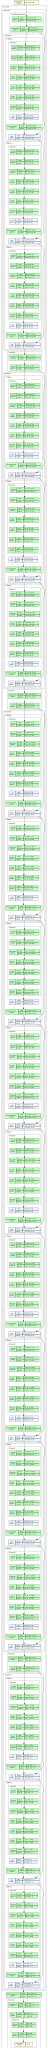

In [ ]:
import torchvision

# Instantiate CNN model and move to computing device (CPU/GPU)
# Create transfer learning model
tl_model = CustomTransferLearningModel(
    num_classes=num_classes,
    model_name="convnext_tiny",
    dropout_rate=DROPOUT_RATE,
    freeze_backbone=True
).to(device)

# Display model summary
summary(tl_model, input_size=input_shape)
model_graph = draw_graph(tl_model, input_size=(BATCH_SIZE,)+input_shape, expand_nested=True, depth=6)
model_graph.visual_graph

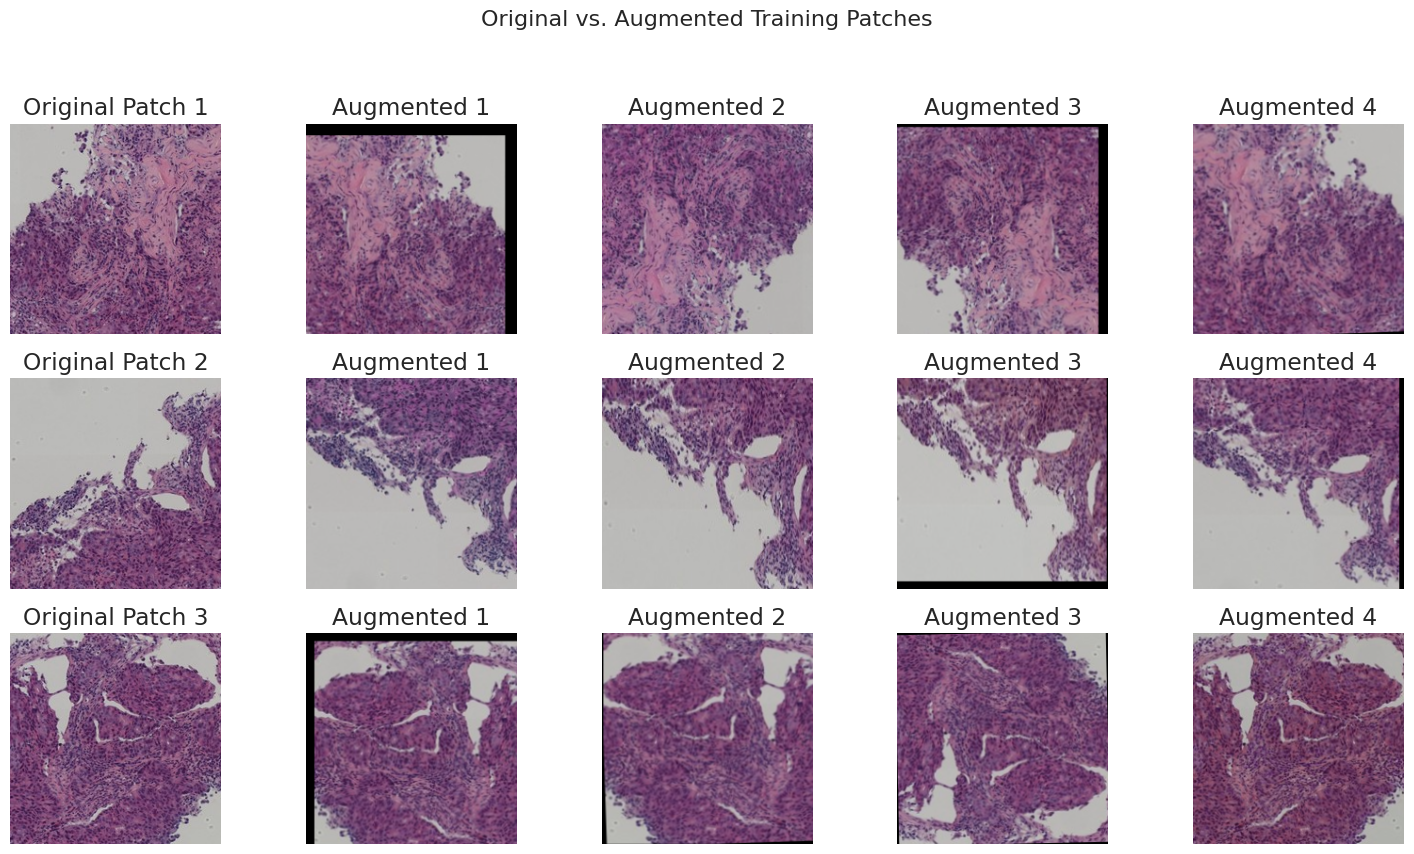

In [ ]:
import matplotlib.pyplot as plt

def visualize_augmented_patches(dataset, transform, num_patches=5, num_augmentations_per_patch=3):
    """
    Visualizes a selection of original patches and their augmented versions.

    Args:
        dataset: The dataset (e.g., train_dataset_transformed) containing original patches.
        transform: The Kornia augmentation sequential pipeline (train_transform_kornia).
        num_patches (int): Number of unique original patches to display.
        num_augmentations_per_patch (int): Number of augmented versions for each original patch.
    """
    fig, axes = plt.subplots(num_patches, num_augmentations_per_patch + 1, figsize=(15, num_patches * 3))
    fig.suptitle('Original vs. Augmented Training Patches', fontsize=16)

    for i in range(num_patches):
        # Get an original patch (and label, though we don't display it here)
        # We unpack all three returned values, but ignore the third (patch_weight)
        original_patch, _, _ = dataset[i] # This is already a tensor in [0, 1]
        original_patch_cuda = original_patch.to(device) # Move to device for Kornia

        # Original Patch Display
        ax = axes[i, 0]
        ax.imshow(original_patch.permute(1, 2, 0).cpu().numpy()) # Convert to HWC for matplotlib
        ax.set_title(f'Original Patch {i+1}')
        ax.axis('off')

        # Augmented Patches Display
        for j in range(num_augmentations_per_patch):
            ax = axes[i, j + 1]

            # Apply augmentation using Kornia
            # Kornia's AugmentationSequential expects a batch, so we add a batch dimension
            augmented_batch = transform(original_patch_cuda.unsqueeze(0))
            augmented_patch = augmented_batch.squeeze(0) # Remove batch dimension

            # De-normalize if Kornia's transform includes normalization for display
            # The `K.Normalize` layer is typically the last in `train_transform_kornia`.
            # We need to reverse it for correct visualization.
            # (assuming mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
            mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(3, 1, 1)
            std = torch.tensor([0.229, 0.224, 0.225], device=device).view(3, 1, 1)
            display_patch = augmented_patch * std + mean

            # Clamp values to [0, 1] as some operations might push them slightly outside
            display_patch = torch.clamp(display_patch, 0, 1)

            ax.imshow(display_patch.permute(1, 2, 0).cpu().numpy()) # Convert to HWC for matplotlib
            ax.set_title(f'Augmented {j+1}')
            ax.axis('off')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()
    plt.close()

# Call the function to display augmented patches
visualize_augmented_patches(train_dataset_transformed, train_transform_kornia, num_patches=3, num_augmentations_per_patch=4)

In [ ]:
# Set up TensorBoard logging and save model architecture
experiment_name = "transfer_learning_convnext_base" # Updated experiment name
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
x = torch.randn(1, input_shape[0], input_shape[1], input_shape[2]).to(device)
writer.add_graph(tl_model, x)

# Define optimizer with L2 regularization (re-initialize for the new model)
optimizer = torch.optim.Adam(tl_model.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)

# Enable mixed precision training for GPU acceleration (re-initialize)
sch_scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

## 🧠 **Model Training**

In [ ]:
#Testing
import time

start = time.time()
for i, (x, y, _) in enumerate(train_loader):
    pass
print("Time to iterate over train_loader:", time.time() - start)

Time to iterate over train_loader: 2.2775630950927734


In [ ]:
%%time
# Train model and track training history
vanilla_model, vanilla_history = fit(
    model=tl_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=sch_scaler,
    device=device,
    writer=writer,
    verbose=1,
    experiment_name="transfer_learning_convnext_base", # Updated experiment name
    patience=PATIENCE
)


# Update best model if current performance is superior
if vanilla_history['val_f1'][-1] > best_performance:
    best_model = vanilla_model
    best_performance = vanilla_history['val_f1'][-1]

# Calculate and print the final validation F1 score
final_val_f1 = round(max(vanilla_history['val_f1']) * 100, 2)
print(f'Final validation F1 score: {final_val_f1}%')

Training 400 epochs...
Batch 0 time: 12.5276s, GPU mem: 0.169 GB
Batch 1 time: 0.1227s, GPU mem: 0.169 GB
Batch 2 time: 0.1224s, GPU mem: 0.169 GB
Batch 3 time: 0.1358s, GPU mem: 0.169 GB
Batch 4 time: 0.1308s, GPU mem: 0.169 GB
Epoch   1/400 | Train: Loss=5.5074, F1 Score=0.3104 | Val: Loss=5.8208, F1 Score=0.3071  GPU mem | 0.16 GB
  TOTAL epoch time: 24.16s
Batch 0 time: 0.2676s, GPU mem: 0.169 GB
Batch 1 time: 0.1786s, GPU mem: 0.169 GB
Batch 2 time: 0.1810s, GPU mem: 0.169 GB
Batch 3 time: 0.2231s, GPU mem: 0.169 GB
Batch 4 time: 0.1973s, GPU mem: 0.169 GB
Epoch   2/400 | Train: Loss=5.2921, F1 Score=0.3578 | Val: Loss=5.7170, F1 Score=0.3300  GPU mem | 0.16 GB
  TOTAL epoch time: 9.50s
Batch 0 time: 0.5574s, GPU mem: 0.169 GB
Batch 1 time: 0.2030s, GPU mem: 0.169 GB
Batch 2 time: 0.1530s, GPU mem: 0.169 GB
Batch 3 time: 0.1423s, GPU mem: 0.169 GB
Batch 4 time: 0.1405s, GPU mem: 0.169 GB
Epoch   3/400 | Train: Loss=5.1853, F1 Score=0.3752 | Val: Loss=5.8109, F1 Score=0.3383  GPU m

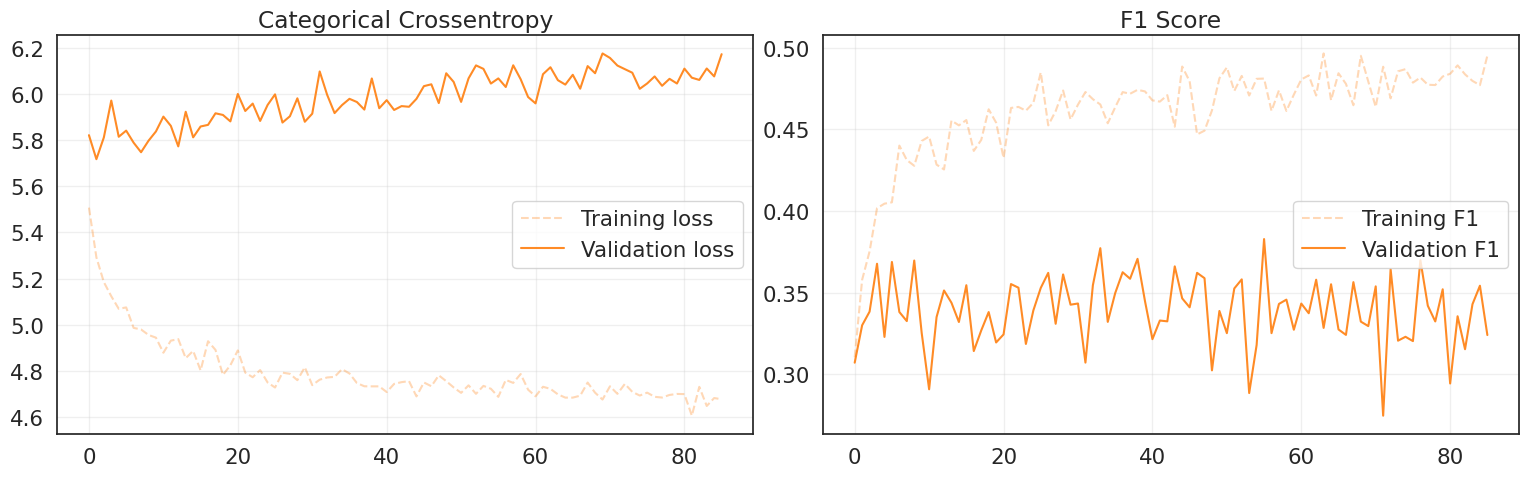

In [ ]:
# @title Plot History
# Create a figure with two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(vanilla_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(vanilla_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Categorical Crossentropy')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation F1 score on the second axis
ax2.plot(vanilla_history['train_f1'], label='Training F1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(vanilla_history['val_f1'], label='Validation F1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

## 📊 **Confusion Matrix for Validation Set**

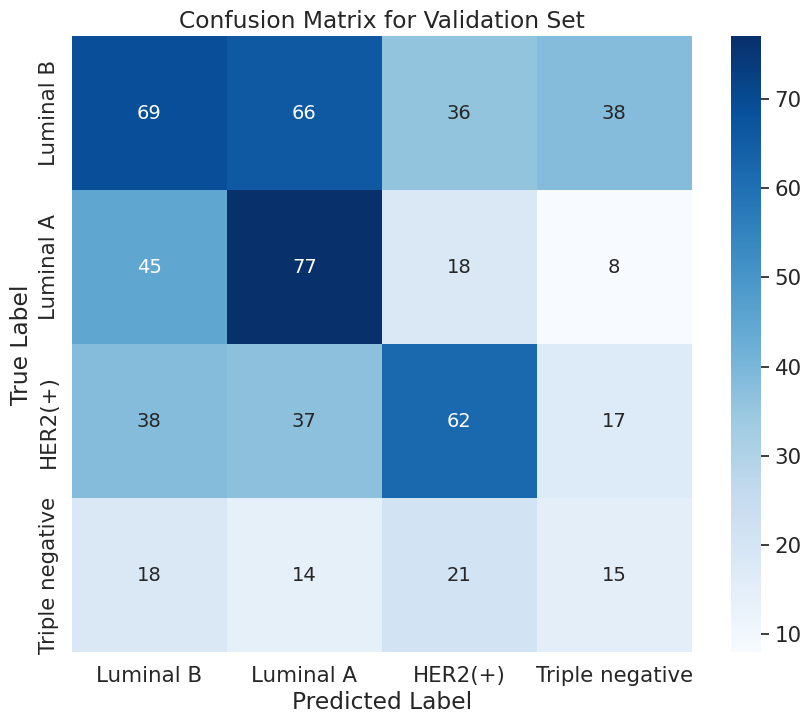

5509

In [ ]:
# Collect predictions and ground truth labels for the validation set
all_val_preds = []
all_val_labels = []

# Set model to evaluation mode
best_model.eval()

with torch.no_grad(): # Disable gradient computation
    for inputs, labels, _ in val_loader: # Corrected: Unpack all three values, ignoring weights
        # Corrected: Remove the extra / 255.0 normalization as PatchDataset already outputs [0, 1] tensors.
        inputs = inputs.to(device).float()
        labels = labels.to(device) # Move labels to device

        # Apply normalization transform for validation data
        inputs = K.Normalize(
            mean=torch.tensor([0.485, 0.456, 0.406], device=device),
            std=torch.tensor([0.229, 0.224, 0.225], device=device)
        )(inputs)

        outputs = best_model(inputs)
        _, predicted = torch.max(outputs.data, 1)

        all_val_preds.extend(predicted.cpu().numpy())
        all_val_labels.extend(labels.cpu().numpy())

# Generate confusion matrix
cm = confusion_matrix(all_val_labels, all_val_preds)

# Get class names from label_mapping
class_names = list(label_mapping.keys())

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Validation Set')
plt.show()

del all_val_preds, all_val_labels, cm, class_names # Free memory
gc.collect()

## 🧰**FINE TUNING**

In [ ]:
# Fine-tuning Parameters
FINE_TUNE_LEARNING_RATE = 5e-5 # Smaller learning rate for fine-tuning
FINE_TUNE_EPOCHS = 200        # Additional epochs for fine-tuning
FINE_TUNE_PATIENCE = 15       # Potentially different patience for early stopping


In [ ]:
def unfreeze_layers(model, num_stages_to_unfreeze=None, unfreeze_all=False):
    """
    Unfreezes layers in the ConvNeXt backbone for fine-tuning.
    Assumes a ConvNeXt architecture where features are in model.backbone.features
    and the classifier head is model.backbone.classifier[2].

    Args:
        model (nn.Module): The model instance.
        num_stages_to_unfreeze (int, optional): Number of final ConvNeXt stages (0-indexed) to unfreeze.
                                                 e.g., 1 for stage 3, 2 for stages 2 and 3.
                                                 If None, only the head remains unfrozen (default behavior).
        unfreeze_all (bool): If True, unfreezes all parameters in the model's features.
    """
    print("\n--- Configuring Trainable Layers ---")
    # First, freeze all parameters in the backbone's features
    for param in model.backbone.features.parameters():
        param.requires_grad = False

    # Ensure the classifier head remains trainable
    for param in model.backbone.classifier[2].parameters():
        param.requires_grad = True

    if unfreeze_all:
        print("Unfreezing ALL backbone layers...")
        for param in model.backbone.features.parameters():
            param.requires_grad = True
    elif num_stages_to_unfreeze is not None:
        print(f"Unfreezing the last {num_stages_to_unfreeze} ConvNeXt stages...")
        # ConvNeXt_Tiny features typically have structure (indices are approximate):
        # 0: stem
        # 1: stage 0 (CNBlock)
        # 2: downsample 1
        # 3: stage 1 (CNBlock)
        # 4: downsample 2
        # 5: stage 2 (CNBlock)
        # 6: downsample 3
        # 7: stage 3 (CNBlock)

        # We iterate backwards through the stages to unfreeze the requested number
        # Indices for stages in ConvNeXt_Tiny are 7 (stage3), 5 (stage2), 3 (stage1), 1 (stage0)
        # Corresponding downsampling layers are 6, 4, 2

        # Map num_stages_to_unfreeze to the relevant feature indices
        stage_map = {
            1: [7, 6],  # Stage 3 + its downsampling
            2: [7, 6, 5, 4], # Stages 2 & 3 + their downsampling
            3: [7, 6, 5, 4, 3, 2], # Stages 1, 2 & 3 + their downsampling
            4: [7, 6, 5, 4, 3, 2, 1, 0] # All stages + stem
        }

        indices_to_unfreeze = stage_map.get(num_stages_to_unfreeze, [])

        for idx in indices_to_unfreeze:
            if idx < len(model.backbone.features):
                for param in model.backbone.features[idx].parameters():
                    param.requires_grad = True
                # print(f"  Unfrozen: model.backbone.features[{idx}] ({model.backbone.features[idx].__class__.__name__})")

    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total_params = sum(p.numel() for p in model.parameters())
    print(f"Total parameters: {total_params}, Trainable parameters: {trainable_params} ({(trainable_params/total_params)*100:.2f}%)")


print("Now you can unfreeze layers and continue training:")

Now you can unfreeze layers and continue training:



--- Configuring Trainable Layers ---
Unfreezing the last 1 ConvNeXt stages...
Total parameters: 27823204, Trainable parameters: 15473668 (55.61%)

Starting fine-tuning for 200 epochs...
Training 200 epochs...
Batch 0 time: 4.7813s, GPU mem: 0.389 GB
Batch 1 time: 0.1503s, GPU mem: 0.389 GB
Batch 2 time: 0.1482s, GPU mem: 0.388 GB
Batch 3 time: 0.1468s, GPU mem: 0.388 GB
Batch 4 time: 0.1499s, GPU mem: 0.389 GB
Epoch   1/200 | Train: Loss=4.8315, F1 Score=0.4524 | Val: Loss=5.8622, F1 Score=0.3682  GPU mem | 0.36 GB
  TOTAL epoch time: 13.41s
Batch 0 time: 0.3138s, GPU mem: 0.388 GB
Batch 1 time: 0.1726s, GPU mem: 0.388 GB
Batch 2 time: 0.1602s, GPU mem: 0.388 GB
Batch 3 time: 0.1432s, GPU mem: 0.388 GB
Batch 4 time: 0.1447s, GPU mem: 0.388 GB
Epoch   2/200 | Train: Loss=4.7469, F1 Score=0.4779 | Val: Loss=5.8899, F1 Score=0.3149  GPU mem | 0.36 GB
  TOTAL epoch time: 9.51s
Batch 0 time: 0.2727s, GPU mem: 0.388 GB
Batch 1 time: 0.1776s, GPU mem: 0.388 GB
Batch 2 time: 0.1666s, GPU mem:

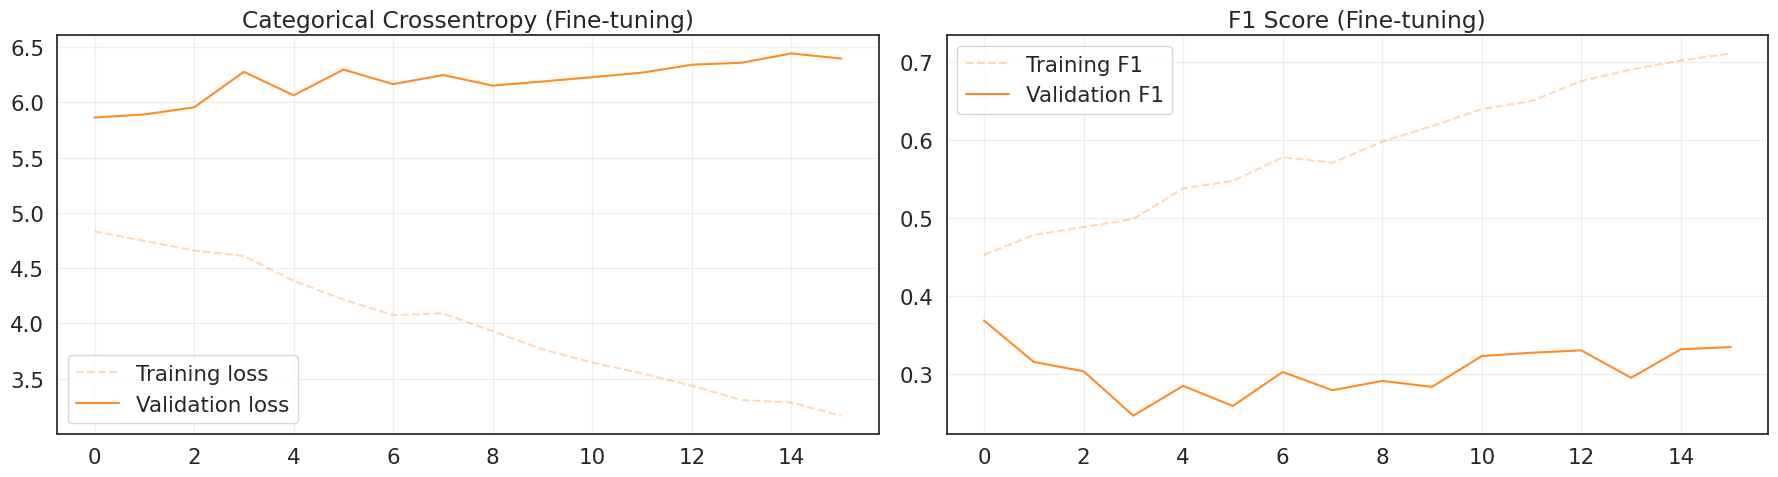

Final fine-tuning validation F1 score: 36.82%


In [ ]:
# --- Fine-tuning Phase --- (after initial training with frozen backbone)

# 1. Unfreeze more layers (e.g., the last stage of ConvNeXt_Tiny)
unfreeze_layers(tl_model, num_stages_to_unfreeze=1) # Unfreeze Stage 3
# Or to unfreeze all:
# unfreeze_layers(tl_model, unfreeze_all=True)

# 2. Re-initialize the optimizer with a lower learning rate
fine_tune_optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, tl_model.parameters()), # Only optimize trainable params
    lr=FINE_TUNE_LEARNING_RATE,
    weight_decay=L2_LAMBDA
)

# 3. Create a new GradScaler for fine-tuning (optional, can reuse if desired)
fine_tune_scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

# 4. Continue training for more epochs
print(f"\nStarting fine-tuning for {FINE_TUNE_EPOCHS} epochs...")
fine_tune_model, fine_tune_history = fit(
    model=tl_model, # Use the already partially trained model
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=FINE_TUNE_EPOCHS,
    criterion=criterion,
    optimizer=fine_tune_optimizer,
    scaler=fine_tune_scaler,
    device=device,
    writer=writer, # Continue using the same TensorBoard writer
    verbose=1,
    experiment_name="transfer_learning_convnext_base_fine_tune", # New experiment name for fine-tuning
    patience=FINE_TUNE_PATIENCE
)

# Plot the fine-tuning history (you might want to combine with initial history later)
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

ax1.plot(fine_tune_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(fine_tune_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Categorical Crossentropy (Fine-tuning)')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(fine_tune_history['train_f1'], label='Training F1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(fine_tune_history['val_f1'], label='Validation F1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score (Fine-tuning)')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

final_fine_tune_f1 = round(max(fine_tune_history['val_f1']) * 100, 2)
print(f'Final fine-tuning validation F1 score: {final_fine_tune_f1}%')


## 📊**INFERENCE**

In [ ]:
# Define TTA transformation (a subset of training augmentations, without normalization)
tta_transform_kornia = K.AugmentationSequential(
    K.RandomResizedCrop((IMG_SIZE, IMG_SIZE), scale=(0.90, 1.0), p=1.0),
    K.RandomHorizontalFlip(p=0.5),
    K.RandomVerticalFlip(p=0.5),
    K.RandomRotation(degrees=5.0, p=0.4),
    K.RandomAffine(degrees=0, translate=(0.05, 0.05),
                   scale=(0.95, 1.05), shear=0),

    # --- Stain / Color ---
    K.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1,
        hue=0.05,
        p=0.4,
    ),
    #K.RandomGaussianBlur((3,3), sigma=(0.1, 0.5), p=0.2),
    data_keys=["input"],
    same_on_batch=False # Apply different augmentations to each image in batch
)

# Number of TTA samples to generate for each image
NUM_TTA_AUGMENTATIONS = 5

In [ ]:
TEST_PATCH_METADATA_CACHE = "/content/test_patch_metadata.pkl"
DRIVE_TEST_PATCH_METADATA_CACHE = os.path.join(current_dir, "test_patch_metadata.pkl")

print(f"Test patch metadata local cache: {TEST_PATCH_METADATA_CACHE}")
print(f"Test patch metadata Drive cache: {DRIVE_TEST_PATCH_METADATA_CACHE}")

Test patch metadata local cache: /content/test_patch_metadata.pkl
Test patch metadata Drive cache: /gdrive/My Drive/the_reluctants_ch2/test_patch_metadata.pkl


In [ ]:
def load_or_create_cache_Test(folder, local_cache_path, drive_cache_path):
    """
    Loads or creates a cache of test image metadata, including filepaths, filenames,
    and coordinates of meaningful patches for each image, with a fallback for images
    yielding no initial valid patches.

    Args:
        folder (str): Path to the folder containing test images.
        local_cache_path (str): Path to the local .pkl file for caching.
        drive_cache_path (str): Path to the Drive .pkl file for persistent caching.

    Returns:
        list: A list of dictionaries, where each dictionary contains
              'original_image_filepath', 'original_image_filename', 'patch_y_coord', 'patch_x_coord'.
    """
    # 1. Check for local cache
    if os.path.exists(local_cache_path):
        print(f"🔵 Loading test patch metadata from fast local storage ({local_cache_path})...")
        with open(local_cache_path, 'rb') as f:
            patch_metadata_list = pickle.load(f)
        return patch_metadata_list

    # 2. If no local cache, check for Drive cache and copy it locally
    elif os.path.exists(drive_cache_path):
        print(f"🔵 Drive cache found for test patch metadata. Copying from Drive → fast local storage...")
        shutil.copy(drive_cache_path, local_cache_path)
        with open(local_cache_path, 'rb') as f:
            patch_metadata_list = pickle.load(f)
        return patch_metadata_list

    # 3. If neither cache exists, generate patches locally
    print(f"🟡 No cache found for test patch metadata — creating it locally...")
    patch_metadata_list = []

    # Default and fallback gray thresholds (scaled for uint8 [0-255])
    initial_gray_threshold_scaled = 0.01 * 255 # Original value
    fallback_gray_threshold_scaled = 0.007 * 255 # Lower threshold for fallback

    # Use tqdm for a progress bar as this can take some time
    all_image_paths = [os.path.join(folder, f) for f in os.listdir(folder)
                       if f.lower().endswith(('.png', '.jpg', '.jpeg')) and not f.startswith("mask") and '(1)' not in f]

    for filepath in tqdm.tqdm(all_image_paths, desc="Extracting test patch coordinates"):
        filename = os.path.basename(filepath)

        img = cv2.imread(filepath)
        if img is None:
            print(f"Warning: Could not load image {filepath}. Skipping.")
            continue

        # Resize the image before patch extraction if RESIZE_FACTOR > 1
        if RESIZE_FACTOR > 1:
            original_h, original_w = img.shape[:2]
            new_h = original_h // RESIZE_FACTOR
            new_w = original_w // RESIZE_FACTOR
            img = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)

        # Convert to RGB (extract_patches expects RGB)
        img_rgb = img[..., ::-1] # BGR to RGB, still uint8

        # Initial attempt to extract patches
        valid_coords = extract_patches(
            img_rgb,
            original_image_filepath=filepath, # Pass the original image filepath
            patch_size=IMG_SIZE,
            stride=IMG_SIZE,
            bg_threshold=0.85 * 255, # Scale bg_threshold for uint8 input
            max_bg_fraction=0.75,
            gray_threshold=initial_gray_threshold_scaled
        )

        # Fallback if no valid patches are found with the initial threshold
        if not valid_coords:
            # print(f"Warning: No meaningful patches found for image {filepath} with initial threshold. Retrying with lower gray_threshold.")
            valid_coords = extract_patches(
                img_rgb,
                original_image_filepath=filepath, # Pass the original image filepath
                patch_size=IMG_SIZE,
                stride=IMG_SIZE,
                bg_threshold=0.85 * 255,
                max_bg_fraction=0.75,
                gray_threshold=fallback_gray_threshold_scaled # Use lower threshold
            )
            if not valid_coords:
                print(f"Critical Warning: Still no patches for {filepath} even with fallback threshold. Skipping this image.")
                continue

        # Store metadata for each valid patch
        for y_coord, x_coord, _, _ in valid_coords:
            patch_metadata_list.append({
                'original_image_filepath': filepath,
                'original_image_filename': filename,
                'patch_y_coord': y_coord,
                'patch_x_coord': x_coord
            })

    print("💾 Saving test patch metadata cache locally and to Drive...")
    with open(local_cache_path, 'wb') as f:
        pickle.dump(patch_metadata_list, f)

    # Also save to Drive for future runs
    shutil.copy(local_cache_path, drive_cache_path)
    print("📤 Cache synced to Drive.")

    return patch_metadata_list

# Load test images metadata
img_path_test = 'test_data_updated'
test_patch_metadata = load_or_create_cache_Test(img_path_test, TEST_PATCH_METADATA_CACHE, DRIVE_TEST_PATCH_METADATA_CACHE)

print(f"Loaded metadata for {len(test_patch_metadata)} test patches.")
gc.collect()

🔵 Drive cache found for test patch metadata. Copying from Drive → fast local storage...
Loaded metadata for 2193 test patches.


0

In [ ]:
class TestPatchDataset(Dataset):
    def __init__(self, patch_metadata, patch_size=224, resize_factor=1):
        """
        Initializes the TestPatchDataset.

        Args:
            patch_metadata (list): A list of dictionaries, where each dictionary contains
                                   'original_image_filepath', 'original_image_filename',
                                   'patch_y_coord', 'patch_x_coord'.
            patch_size (int): The size of the square patches to extract.
            resize_factor (int): Factor by which the original image was downsampled
                                 before patch extraction coordinates were determined.
        """
        self.patch_metadata = patch_metadata
        self.patch_size = patch_size
        self.resize_factor = resize_factor

        # Cache to store loaded images to avoid re-reading from disk for multiple patches
        self.image_cache = {}

        # Pre-process image paths to speed up access
        self.image_paths = [d['original_image_filepath'] for d in patch_metadata]

    def __len__(self):
        return len(self.patch_metadata)

    def __getitem__(self, idx):
        metadata_item = self.patch_metadata[idx]
        filepath = metadata_item['original_image_filepath']
        y_coord = metadata_item['patch_y_coord']
        x_coord = metadata_item['patch_x_coord']
        original_filename = metadata_item['original_image_filename']

        # Load image from cache or disk
        if filepath not in self.image_cache:
            img = cv2.imread(filepath)
            if img is None:
                raise FileNotFoundError(f"Could not load image {filepath}")

            # Resize the image if it was resized during metadata generation
            if self.resize_factor > 1:
                original_h, original_w = img.shape[:2]
                new_h = original_h // self.resize_factor
                new_w = original_w // self.resize_factor
                img = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)

            # Convert BGR to RGB for consistency (cv2 reads as BGR)
            img_rgb = img[..., ::-1]
            self.image_cache[filepath] = img_rgb
        else:
            img_rgb = self.image_cache[filepath]

        # Extract the specific patch
        patch_np = img_rgb[y_coord : y_coord + self.patch_size, x_coord : x_coord + self.patch_size]

        # Convert to float32 and normalize to [0, 1]
        patch_np = (patch_np / 255.0).astype(np.float32)

        # Convert to PyTorch tensor (C, H, W)
        patch_tensor = torch.tensor(patch_np, dtype=torch.float32).permute(2, 0, 1)

        # Return the patch and the original filename for aggregation
        return patch_tensor, original_filename

In [ ]:
# Create the TestPatchDataset
test_dataset_patches = TestPatchDataset(
    patch_metadata=test_patch_metadata,
    patch_size=IMG_SIZE,
    resize_factor=RESIZE_FACTOR
)

# Create a DataLoader for the test dataset
# Note: For DataLoader, we need a custom collate_fn if `original_filename` is returned directly.
def collate_fn_test(batch):
    patches = [item[0] for item in batch]
    filenames = [item[1] for item in batch]
    return torch.stack(patches), filenames

test_loader = DataLoader(
    test_dataset_patches,
    batch_size=BATCH_SIZE,
    shuffle=False, # No need to shuffle for inference
    drop_last=False,
    num_workers=os.cpu_count() or 2, # Use all available CPU cores or a default of 2
    pin_memory=True,  # Faster GPU transfer
    pin_memory_device="cuda" if torch.cuda.is_available() else "",
    prefetch_factor=2, # Load 2 batches ahead
    collate_fn=collate_fn_test
)

print(f"Number of batches in test_loader: {len(test_loader)}")
print(f"Total number of patches for inference: {len(test_dataset_patches)}")

# Clear original test_patch_metadata to save memory as it's now in the dataset
del test_patch_metadata
gc.collect()

Number of batches in test_loader: 35
Total number of patches for inference: 2193


0

In [ ]:
# Collect predictions and ground truth labels for the validation set
all_test_preds_with_filenames = []

# Set model to evaluation mode
best_model.eval()

# Inverse mapping for labels
inverse_label_mapping = {v: k for k, v in label_mapping.items()}

# Progress bar for the DataLoader iteration
tqdm_test_loader = tqdm.tqdm(test_loader, desc="Inferring on test patches with TTA")

with torch.no_grad():  # Disable gradient computation
    for patches_batch, original_filenames_batch in tqdm_test_loader:
        patches_batch = patches_batch.to(device)

        # Initialize a tensor to store aggregated logits for this batch
        # The size will be (BATCH_SIZE, NUM_CLASSES)
        aggregated_logits = torch.zeros(patches_batch.shape[0], num_classes, device=device)

        for _ in range(NUM_TTA_AUGMENTATIONS):
            # Apply TTA augmentations (excluding normalization)
            augmented_patches = tta_transform_kornia(patches_batch)

            # Apply normalization (which is done consistently for all TTA samples)
            normalized_augmented_patches = K.Normalize(
                mean=torch.tensor([0.485, 0.456, 0.406], device=device),
                std=torch.tensor([0.229, 0.224, 0.225], device=device)
            )(augmented_patches)

            # Forward pass: get model predictions (logits)
            logits = best_model(normalized_augmented_patches)

            # Sum up the logits. We'll average them later implicitly with argmax.
            aggregated_logits += logits

        # Get predicted class indices from the aggregated logits
        _, predicted_classes = torch.max(aggregated_logits, 1)

        # Extend the list with (filename, prediction) tuples
        for filename, pred_class in zip(original_filenames_batch, predicted_classes.cpu().numpy()):
            all_test_preds_with_filenames.append({'filename': filename, 'prediction': pred_class})

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache() # Clear unused GPU memory after inference

print("Aggregating predictions per image...")

# Aggregate predictions for each original image
image_predictions = {} # Stores list of predictions for each image
for item in all_test_preds_with_filenames:
    filename = item['filename']
    prediction = item['prediction']
    if filename not in image_predictions:
        image_predictions[filename] = []
    image_predictions[filename].append(prediction)

# Determine the final prediction for each image (e.g., by majority vote)
final_predictions = []
for filename, preds in image_predictions.items():
    # Use mode (most frequent prediction) for aggregation
    # If there's a tie, np.bincount().argmax() returns the smallest index
    counts = np.bincount(preds)
    final_pred_numerical = np.argmax(counts)
    final_pred_label = inverse_label_mapping[final_pred_numerical]
    final_predictions.append({
        'sample_index': filename,
        'label': final_pred_label
    })

# Create a Pandas DataFrame with 'sample_index' and 'label'
df_submission_tta = pd.DataFrame(final_predictions)

# Sort the DataFrame by 'sample_index' to ensure consistent submission order
df_submission_tta = df_submission_tta.sort_values(by="sample_index").reset_index(drop=True)

df_submission_tta.to_csv("submission_tta.csv", index=False)

print("Submission file 'submission_tta.csv' created successfully using TTA.")
display(df_submission_tta.head())
print(f"Number of lines in the submission DataFrame with TTA: {len(df_submission_tta)}")

Inferring on test patches with TTA: 100%|██████████| 35/35 [03:41<00:00,  6.33s/it]


Aggregating predictions per image...
Submission file 'submission_tta.csv' created successfully using TTA.


,sample_index,label
0,img_0000.png,Luminal A
1,img_0001.png,Luminal B
2,img_0002.png,Luminal B
3,img_0003.png,Triple negative
4,img_0004.png,Luminal B


Number of lines in the submission DataFrame with TTA: 477
